# FiQA EDA — Financial Retrieval

Exploratory analysis of the BEIR FiQA corpus, queries, and qrels to guide baseline and model choices for semantic/financial search.

**Questions this notebook answers**
1. Is the data clean and split-safe?
2. What do corpus documents and queries look like?
3. How sparse / multi-positive are relevance labels?
4. Is lexical overlap high enough for a strong BM25 baseline?
5. What finance-specific text patterns matter for tokenization and matching?


In [1]:
from __future__ import annotations

import hashlib
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_rows", 40)
sns.set_theme(style="whitegrid", context="notebook")
RNG = np.random.default_rng(42)

ROOT = Path(".").resolve()
CORPUS_PATH = ROOT / "fiqa" / "corpus" / "corpus-00000-of-00001.parquet"
QUERIES_PATH = ROOT / "fiqa" / "queries" / "queries-00000-of-00001.parquet"
QRELS_DIR = ROOT / "fiqa-qrels"

print("ROOT:", ROOT)


ROOT: /Users/tomhait/git/tom.aharon-hait/projects/financial_retrieval


## 1. Load data


In [2]:
corpus = pd.read_parquet(CORPUS_PATH)
queries = pd.read_parquet(QUERIES_PATH)

for df in (corpus, queries):
    df["_id"] = df["_id"].astype(str)
    df["title"] = df["title"].fillna("").astype(str)
    df["text"] = df["text"].fillna("").astype(str)

qrels = {}
for split in ("train", "dev", "test"):
    df = pd.read_csv(QRELS_DIR / f"{split}.tsv", sep="\t")
    df["query-id"] = df["query-id"].astype(str)
    df["corpus-id"] = df["corpus-id"].astype(str)
    qrels[split] = df

print("Corpus:", corpus.shape)
print("Queries:", queries.shape)
for split, df in qrels.items():
    print(f"Qrels {split}: {df.shape[0]:,} judgments | {df['query-id'].nunique():,} queries")

display(corpus.head(2))
display(queries.head(2))
display(qrels["train"].head(3))
display(qrels["dev"].head(3))
display(qrels["test"].head(3))


Corpus: (57638, 3)
Queries: (6648, 3)
Qrels train: 14,166 judgments | 5,500 queries
Qrels dev: 1,238 judgments | 500 queries
Qrels test: 1,706 judgments | 648 queries


,_id,title,text
0,3,,"I'm not saying I don't like the idea of on-the-job training too, but you can't expect the company to do that. Training workers is not th..."
1,31,,"So nothing preventing false ratings besides additional scrutiny from the market/investors, but there are some newer controls in place to..."


,_id,title,text
0,0,,What is considered a business expense on a business trip?
1,4,,Business Expense - Car Insurance Deductible For Accident That Occurred During a Business Trip


,query-id,corpus-id,score
0,0,18850,1
1,4,196463,1
2,5,69306,1


,query-id,corpus-id,score
0,1,14255,1
1,2,308938,1
2,3,296717,1


,query-id,corpus-id,score
0,8,566392,1
1,8,65404,1
2,15,325273,1


## 2. Integrity & split safety


In [3]:
corpus_ids = set(corpus["_id"])
query_ids = set(queries["_id"])

integrity_rows = []
for split, df in qrels.items():
    missing_q = (~df["query-id"].isin(query_ids)).sum()
    missing_d = (~df["corpus-id"].isin(corpus_ids)).sum()
    integrity_rows.append(
        {
            "split": split,
            "n_judgments": len(df),
            "n_queries": df["query-id"].nunique(),
            "n_docs": df["corpus-id"].nunique(),
            "missing_query_ids": int(missing_q),
            "missing_corpus_ids": int(missing_d),
            "score_values": sorted(df["score"].unique().tolist()),
            "duplicate_pairs": int(df.duplicated(["query-id", "corpus-id"]).sum()),
        }
    )

integrity = pd.DataFrame(integrity_rows)
display(integrity)

split_query_sets = {s: set(df["query-id"]) for s, df in qrels.items()}
print("Query overlap train∩dev:", len(split_query_sets["train"] & split_query_sets["dev"]))
print("Query overlap train∩test:", len(split_query_sets["train"] & split_query_sets["test"]))
print("Query overlap dev∩test:", len(split_query_sets["dev"] & split_query_sets["test"]))

all_judged_queries = set().union(*split_query_sets.values())
orphan_queries = query_ids - all_judged_queries
print(f"Queries with no qrels in any split: {len(orphan_queries):,} / {len(query_ids):,}")

split_doc_sets = {s: set(df["corpus-id"]) for s, df in qrels.items()}
print("Relevant-doc overlap train∩test:", len(split_doc_sets["train"] & split_doc_sets["test"]))
print("Relevant-doc overlap train∩dev:", len(split_doc_sets["train"] & split_doc_sets["dev"]))
print("Relevant-doc overlap dev∩test:", len(split_doc_sets["dev"] & split_doc_sets["test"]))


,split,n_judgments,n_queries,n_docs,missing_query_ids,missing_corpus_ids,score_values,duplicate_pairs
0,train,14166,5500,14166,0,0,[1],0
1,dev,1238,500,1238,0,0,[1],0
2,test,1706,648,1706,0,0,[1],0


Query overlap train∩dev: 0
Query overlap train∩test: 0
Query overlap dev∩test: 0
Queries with no qrels in any split: 0 / 6,648
Relevant-doc overlap train∩test: 0
Relevant-doc overlap train∩dev: 0
Relevant-doc overlap dev∩test: 0


## 3. Corpus profile


Title empty rate: 1.0
Text empty rate: 0.0006592872757555779
Exact duplicate texts: 39
Unique texts: 57599


,char_len,token_len
count,57638.000000,57638.000000
mean,767.210816,136.272355
std,738.614266,131.150875
min,0.000000,0.000000
5%,221.000000,40.000000
25%,329.000000,58.000000
50%,522.000000,93.000000
75%,935.000000,167.000000
95%,2097.000000,375.000000
99%,3697.630000,655.000000


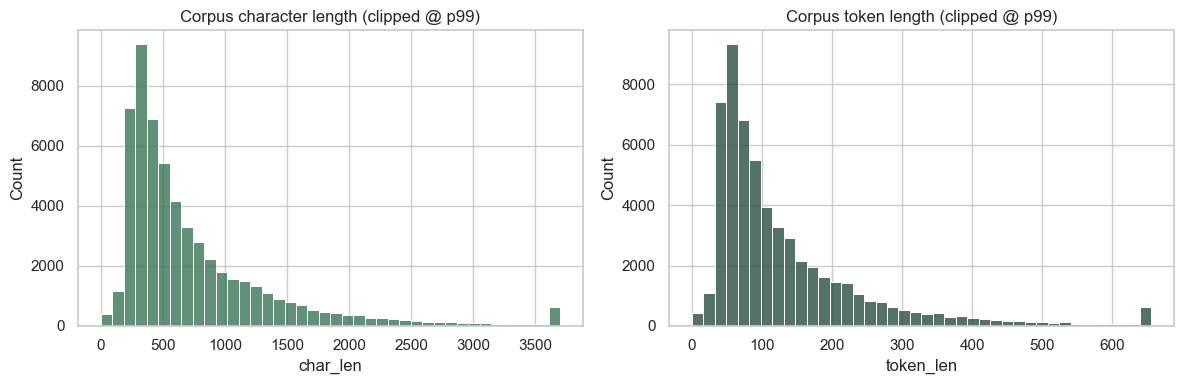

Docs with < 10 tokens: 180
Docs with > 1000 tokens: 137


,_id,token_len,text
741,7915,0,
1158,12229,0,
1329,14135,0,


,_id,token_len,text
40154,418057,3005,"""When considering such a major life decision, with such high potential costs and high potential rewards, I encourage you to consider mul..."
44398,462036,2437,"""This may be a bit advanced now, but once you start really working and get a place, I think this will apply more... Do I set up a bank a..."
3914,40821,2199,"""I'm afraid you have missed a few of the outcomes commonly faced by millions of Americans, so I would like to take a moment to discuss a..."


In [3]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?", re.I)


def tokenize(text: str) -> list[str]:
    return TOKEN_RE.findall(text.lower())


corpus = corpus.copy()
corpus["char_len"] = corpus["text"].str.len()
corpus["token_len"] = corpus["text"].map(lambda t: len(tokenize(t)))
corpus["title_empty"] = corpus["title"].str.strip().eq("")
corpus["text_empty"] = corpus["text"].str.strip().eq("")
corpus["text_hash"] = corpus["text"].map(lambda t: hashlib.md5(t.encode("utf-8")).hexdigest())

print("Title empty rate:", float(corpus["title_empty"].mean()))
print("Text empty rate:", float(corpus["text_empty"].mean()))
print("Exact duplicate texts:", int(corpus["text_hash"].duplicated().sum()))
print("Unique texts:", corpus["text_hash"].nunique())
display(corpus[["char_len", "token_len"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(corpus["char_len"].clip(upper=corpus["char_len"].quantile(0.99)), bins=40, ax=axes[0], color="#2c6e49")
axes[0].set_title("Corpus character length (clipped @ p99)")
sns.histplot(corpus["token_len"].clip(upper=corpus["token_len"].quantile(0.99)), bins=40, ax=axes[1], color="#1b4332")
axes[1].set_title("Corpus token length (clipped @ p99)")
plt.tight_layout()
plt.show()

print("Docs with < 10 tokens:", int((corpus["token_len"] < 10).sum()))
print("Docs with > 1000 tokens:", int((corpus["token_len"] > 1000).sum()))
display(corpus.nsmallest(3, "token_len")[["_id", "token_len", "text"]])
display(
    corpus.nlargest(3, "token_len")[["_id", "token_len", "text"]].assign(
        text=lambda d: d["text"].str[:300] + "..."
    )
)


Finance-term hit rate (any): 0.6194
count    5000.000000
mean        1.809000
std         2.396261
min         0.000000
25%         0.000000
50%         1.000000
75%         3.000000
max        21.000000
Name: finance_hits, dtype: float64


,term,count
0,money,2811
1,don't,1646
2,pay,1643
3,people,1610
4,it's,1576
5,time,1451
6,them,1431
7,tax,1412
8,because,1397
9,make,1384


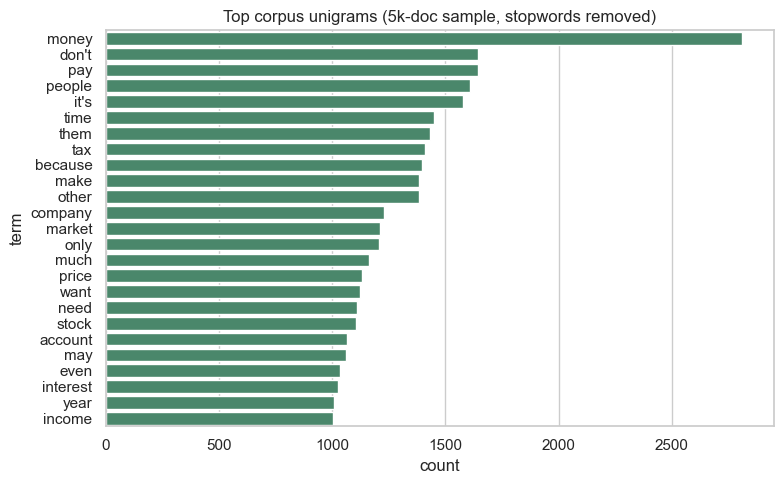

In [4]:
FINANCE_TERMS = {
    "stock", "stocks", "equity", "equities", "bond", "bonds", "etf", "etfs", "mutual",
    "dividend", "dividends", "option", "options", "call", "put", "futures", "forex",
    "ira", "roth", "401k", "hsa", "pension", "retirement", "brokerage",
    "portfolio", "index", "fund", "funds", "nav", "yield", "coupon", "maturity",
    "pe", "eps", "ebitda", "revenue", "earnings", "valuation", "market",
    "interest", "mortgage", "loan", "debt", "credit", "tax", "taxes", "irs",
    "inflation", "fed", "crypto", "bitcoin", "btc", "volatility", "risk",
    "hedge", "leverage", "margin", "short", "long", "bull", "bear", "liquidity",
}

sample_idx = RNG.choice(len(corpus), size=min(5000, len(corpus)), replace=False)
sample_docs = corpus.iloc[sample_idx].copy()


def finance_term_hits(text: str) -> int:
    toks = set(tokenize(text))
    return sum(1 for t in FINANCE_TERMS if t in toks)


sample_docs["finance_hits"] = sample_docs["text"].map(finance_term_hits)
print("Finance-term hit rate (any):", float((sample_docs["finance_hits"] > 0).mean()))
print(sample_docs["finance_hits"].describe())

STOP = {
    "the", "a", "an", "and", "or", "to", "of", "in", "on", "for", "is", "are", "was", "were",
    "be", "been", "being", "it", "this", "that", "with", "as", "at", "by", "from", "you",
    "your", "i", "my", "we", "our", "they", "their", "not", "if", "but", "so", "can",
    "will", "would", "should", "could", "have", "has", "had", "do", "does", "did",
    "about", "into", "than", "then", "there", "what", "when", "which", "who", "how",
    "more", "also", "just", "like", "get", "one", "out", "up", "all", "any", "some",
}
counter = Counter()
for text in sample_docs["text"]:
    counter.update(t for t in tokenize(text) if t not in STOP and len(t) > 2)

top_terms = pd.DataFrame(counter.most_common(25), columns=["term", "count"])
display(top_terms)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=top_terms, y="term", x="count", ax=ax, color="#40916c")
ax.set_title("Top corpus unigrams (5k-doc sample, stopwords removed)")
plt.tight_layout()
plt.show()


## 4. Query profile


Title empty rate: 1.0


,char_len,token_len
count,6648.000000,6648.000000
mean,61.709838,10.988869
std,22.814805,4.426033
min,14.000000,2.000000
5%,28.000000,5.000000
25%,45.000000,8.000000
50%,60.000000,10.000000
75%,76.000000,14.000000
95%,103.000000,19.000000
max,166.000000,31.000000


,rate
is_are,0.200511
how,0.154633
what,0.133424
why,0.064832
where,0.015493
when,0.013538
best,0.012635
which,0.006318


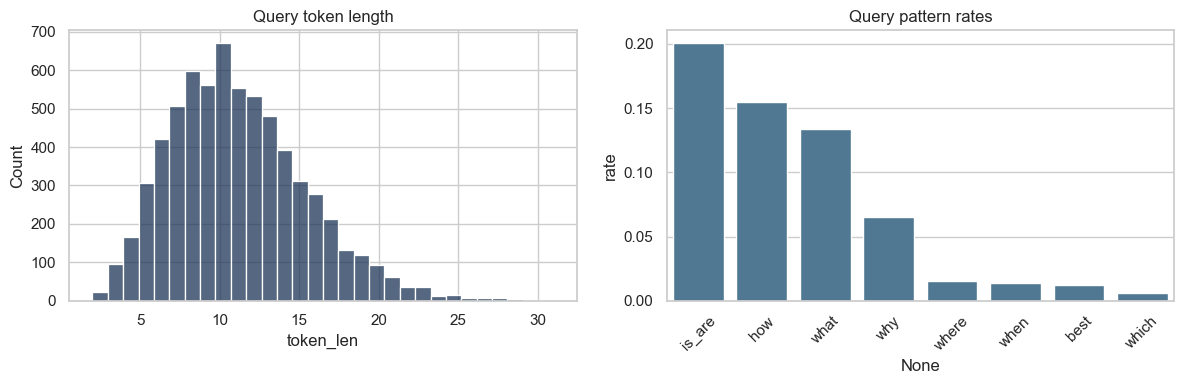

,_id,token_len,text
385,871,2,Value investing
740,1580,2,Money Structuring
1688,3278,2,Payroll reimbursments
2210,4119,2,Economics Books
2520,4704,2,Finance algebra


,_id,token_len,text
6142,6612,31,"If I have a lot of debt and the housing market is rising, should I rent and slowly pay off my debt or buy and roll the debt into a mortg..."
3508,6492,30,If my put option reaches expiration on etrade and I don't log in to the site will it automatically exercise if it's in the money or be a...
5914,3608,30,"For a major expensive home renovation (e.g. addition, finished basement, or new kitchen) should one pay cash or finance with a loan? Wou..."
2016,3810,29,"I am trying to start a “hedge fund,” and by that, I really just mean I have a very specific and somewhat simple investment thesis that I..."
3080,5654,29,"If I put a large down payment (over 50%) towards a car loan, can I reduce my interest rate and is it smart to even put that much down?"


In [5]:
queries = queries.copy()
queries["char_len"] = queries["text"].str.len()
queries["token_len"] = queries["text"].map(lambda t: len(tokenize(t)))
queries["title_empty"] = queries["title"].str.strip().eq("")

WH_PATTERNS = {
    "what": r"^\s*what\b",
    "how": r"^\s*how\b",
    "why": r"^\s*why\b",
    "when": r"^\s*when\b",
    "where": r"^\s*where\b",
    "which": r"^\s*which\b",
    "is_are": r"^\s*(?:is|are|do|does|can|should|will)\b",
    "best": r"\bbest\b",
}

for name, pat in WH_PATTERNS.items():
    queries[f"pat_{name}"] = queries["text"].str.contains(pat, case=False, regex=True)

print("Title empty rate:", float(queries["title_empty"].mean()))
display(queries[["char_len", "token_len"]].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]))

pattern_rates = (
    pd.Series({k: queries[f"pat_{k}"].mean() for k in WH_PATTERNS})
    .sort_values(ascending=False)
    .rename("rate")
    .to_frame()
)
display(pattern_rates)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(queries["token_len"], bins=30, ax=axes[0], color="#1d3557")
axes[0].set_title("Query token length")
sns.barplot(x=pattern_rates.index, y=pattern_rates["rate"], ax=axes[1], color="#457b9d")
axes[1].set_title("Query pattern rates")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

display(queries.nsmallest(5, "token_len")[["_id", "token_len", "text"]])
display(queries.nlargest(5, "token_len")[["_id", "token_len", "text"]])


## 5. Relevance structure (qrels)


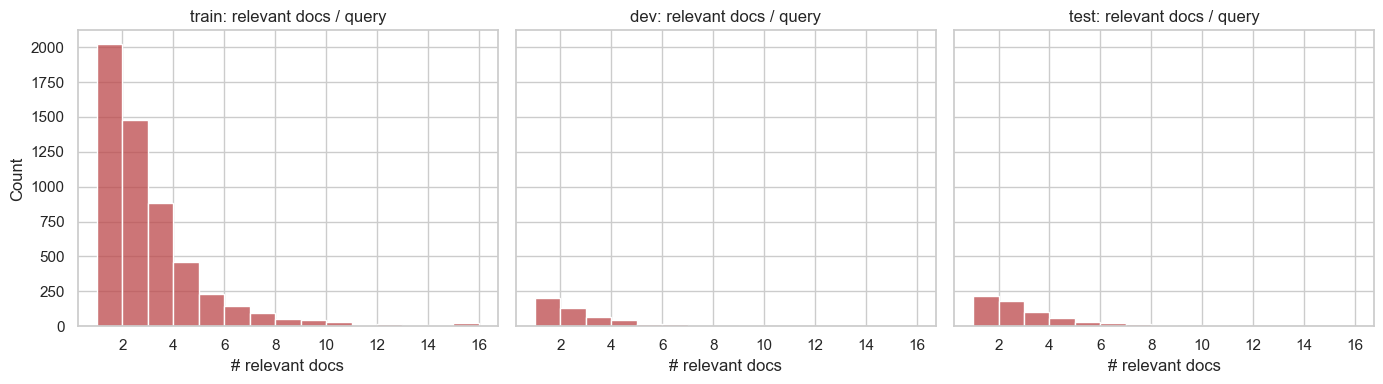

,split,queries,judgments,unique_relevant_docs,mean_rel_per_query,median_rel_per_query,p90_rel_per_query,max_rel_per_query,pct_single_relevant
0,train,5500,14166,14166,2.575636,2.0,5.0,23,0.367091
1,dev,500,1238,1238,2.476000,2.0,5.0,20,0.400000
2,test,648,1706,1706,2.632716,2.0,5.0,15,0.339506


Corpus docs ever marked relevant: 17,110 / 57,638 (29.7%)
Train: docs relevant to >1 query: 0
count    14166.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
dtype: float64


,corpus-id,n_queries
0,100009,1
1,460353,1
2,460014,1
3,460058,1
4,460064,1
5,460175,1
6,460193,1
7,460196,1
8,460230,1
9,460241,1


In [6]:
qrels_stats = []
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)

for ax, (split, df) in zip(axes, qrels.items()):
    per_q = df.groupby("query-id").size()
    qrels_stats.append(
        {
            "split": split,
            "queries": df["query-id"].nunique(),
            "judgments": len(df),
            "unique_relevant_docs": df["corpus-id"].nunique(),
            "mean_rel_per_query": per_q.mean(),
            "median_rel_per_query": per_q.median(),
            "p90_rel_per_query": per_q.quantile(0.9),
            "max_rel_per_query": per_q.max(),
            "pct_single_relevant": float((per_q == 1).mean()),
        }
    )
    sns.histplot(per_q.clip(upper=15), bins=range(1, 17), ax=ax, color="#bc4749")
    ax.set_title(f"{split}: relevant docs / query")
    ax.set_xlabel("# relevant docs")

plt.tight_layout()
plt.show()

qrels_summary = pd.DataFrame(qrels_stats)
display(qrels_summary)

all_relevant_docs = set().union(*(set(df["corpus-id"]) for df in qrels.values()))
print(
    f"Corpus docs ever marked relevant: {len(all_relevant_docs):,} / {len(corpus):,}"
    f" ({len(all_relevant_docs)/len(corpus):.1%})"
)

doc_pop = qrels["train"].groupby("corpus-id").size().sort_values(ascending=False)
print("Train: docs relevant to >1 query:", int((doc_pop > 1).sum()))
print(doc_pop.describe())
display(doc_pop.head(10).rename("n_queries").to_frame().reset_index())


## 6. Query-document lexical relationship

Compare gold relevant pairs vs random negatives on token overlap. High gold overlap favors BM25; low overlap favors dense/hybrid retrieval.


jaccard                     query_coverage            \
                     mean    median       std           mean    median   
pair_type                                                                
gold             0.056122  0.048544  0.036916       0.481292  0.500000   
random_negative  0.028868  0.025000  0.022200       0.220637  0.214286   

                          shared_terms                   
                      std         mean median       std  
pair_type                                                
gold             0.213779     5.155667    5.0  2.889559  
random_negative  0.145641     2.429333    2.0  1.888084

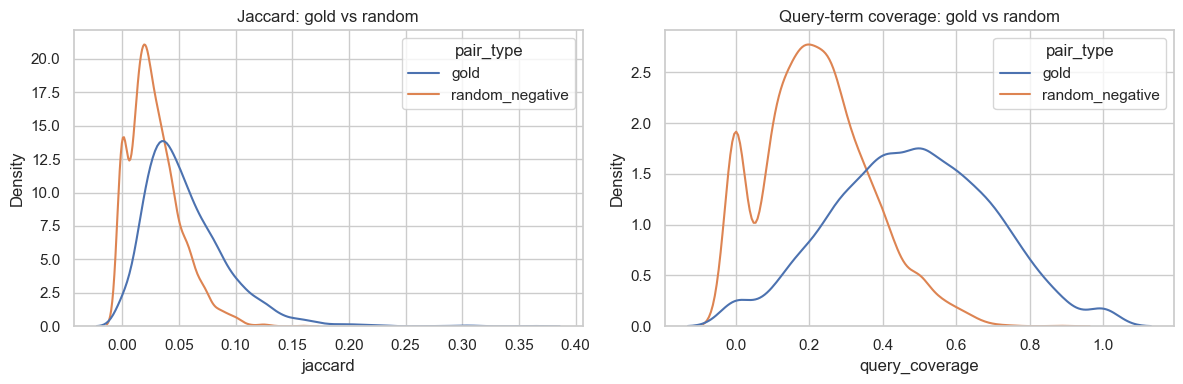

Gold pairs with query coverage == 0: 0.024
Gold pairs with query coverage >= 0.5: 0.5156666666666667


In [7]:
corpus_tok = {i: set(tokenize(t)) for i, t in zip(corpus["_id"], corpus["text"])}
query_tok = {i: set(tokenize(t)) for i, t in zip(queries["_id"], queries["text"])}
corpus_id_list = corpus["_id"].tolist()


def jaccard(a: set[str], b: set[str]) -> float:
    if not a and not b:
        return 0.0
    inter = len(a & b)
    union = len(a | b)
    return inter / union if union else 0.0


def overlap_coeff(a: set[str], b: set[str]) -> float:
    """Fraction of query terms found in the document: |q & d| / |q|."""
    if not a:
        return 0.0
    return len(a & b) / len(a)


def pair_stats(pairs: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for qid, did in zip(pairs["query-id"], pairs["corpus-id"]):
        qt, dt = query_tok[qid], corpus_tok[did]
        rows.append(
            {
                "jaccard": jaccard(qt, dt),
                "query_coverage": overlap_coeff(qt, dt),
                "shared_terms": len(qt & dt),
                "query_len": len(qt),
                "doc_len": len(dt),
            }
        )
    return pd.DataFrame(rows)


def sample_random_negatives(qrel_df: pd.DataFrame, n: int = 3000) -> pd.DataFrame:
    """Sample (query, non-relevant doc) pairs for the given qrels split."""
    rel_map = qrel_df.groupby("query-id")["corpus-id"].apply(set).to_dict()
    qids = list(rel_map.keys())
    rows = []
    attempts = 0
    while len(rows) < n and attempts < n * 20:
        attempts += 1
        qid = qids[int(RNG.integers(0, len(qids)))]
        did = corpus_id_list[int(RNG.integers(0, len(corpus_id_list)))]
        if did not in rel_map[qid]:
            rows.append({"query-id": qid, "corpus-id": did})
    return pd.DataFrame(rows)


gold = qrels["train"].sample(n=min(3000, len(qrels["train"])), random_state=42)
neg = sample_random_negatives(qrels["train"], n=3000)

gold_stats = pair_stats(gold).assign(pair_type="gold")
neg_stats = pair_stats(neg).assign(pair_type="random_negative")
overlap_cmp = pd.concat([gold_stats, neg_stats], ignore_index=True)

summary = overlap_cmp.groupby("pair_type")[["jaccard", "query_coverage", "shared_terms"]].agg(
    ["mean", "median", "std"]
)
display(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.kdeplot(data=overlap_cmp, x="jaccard", hue="pair_type", ax=axes[0], common_norm=False)
axes[0].set_title("Jaccard: gold vs random")
sns.kdeplot(data=overlap_cmp, x="query_coverage", hue="pair_type", ax=axes[1], common_norm=False)
axes[1].set_title("Query-term coverage: gold vs random")
plt.tight_layout()
plt.show()

print("Gold pairs with query coverage == 0:", float((gold_stats["query_coverage"] == 0).mean()))
print("Gold pairs with query coverage >= 0.5:", float((gold_stats["query_coverage"] >= 0.5).mean()))


,count,mean,std,min,25%,50%,75%,max
pair_type,,,,,,,,
gold,3000.0,9.578182,6.330787,0.0,4.967969,8.700060,13.090357,43.672754
random_negative,3000.0,1.680682,1.902009,0.0,0.264499,0.999683,2.552649,15.168657


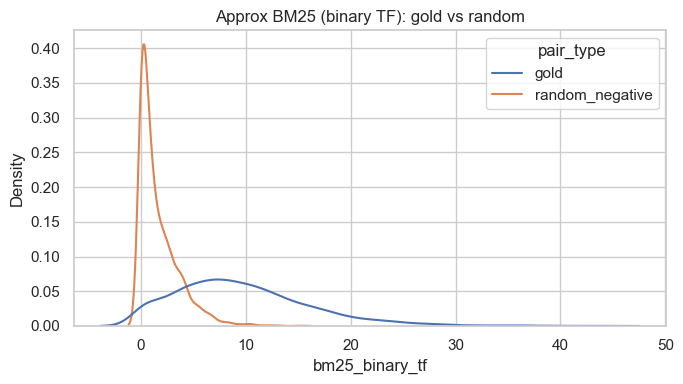

P(BM25_gold > BM25_random) on matched sample size: 0.904


In [8]:
# Lightweight BM25-style score for gold vs random (binary TF approximation)
N = len(corpus)
avgdl = float(np.mean([len(corpus_tok[i]) for i in corpus_id_list]))
df_count = Counter()
for toks in corpus_tok.values():
    df_count.update(toks)


def idf(term: str) -> float:
    n_q = df_count.get(term, 0)
    return np.log(1 + (N - n_q + 0.5) / (n_q + 0.5))


def bm25_score(qid: str, did: str, k1: float = 1.2, b: float = 0.75) -> float:
    q_terms = query_tok[qid]
    d_terms = corpus_tok[did]
    if not q_terms or not d_terms:
        return 0.0
    score = 0.0
    dl = len(d_terms)
    for term in q_terms:
        if term not in d_terms:
            continue
        freq = 1.0  # binary TF approximation
        denom = freq + k1 * (1 - b + b * dl / avgdl)
        score += idf(term) * (freq * (k1 + 1)) / denom
    return float(score)


gold_bm25 = [bm25_score(q, d) for q, d in zip(gold["query-id"], gold["corpus-id"])]
neg_bm25 = [bm25_score(q, d) for q, d in zip(neg["query-id"], neg["corpus-id"])]

bm25_df = pd.DataFrame(
    {
        "bm25_binary_tf": gold_bm25 + neg_bm25,
        "pair_type": ["gold"] * len(gold_bm25) + ["random_negative"] * len(neg_bm25),
    }
)
display(bm25_df.groupby("pair_type")["bm25_binary_tf"].describe())

fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(data=bm25_df, x="bm25_binary_tf", hue="pair_type", ax=ax, common_norm=False)
ax.set_title("Approx BM25 (binary TF): gold vs random")
plt.tight_layout()
plt.show()

paired = np.array(gold_bm25) > np.array(neg_bm25[: len(gold_bm25)])
print("P(BM25_gold > BM25_random) on matched sample size:", float(paired.mean()))


## 7. Finance-specific text patterns


,queries,corpus_sample
currency,0.018652,0.1526
percent,0.016998,0.1698
ticker_like,0.350782,0.7524
account_products,0.035199,0.0394
options,0.061221,0.1618
tax,0.098977,0.1496
numbers,0.083935,0.4584


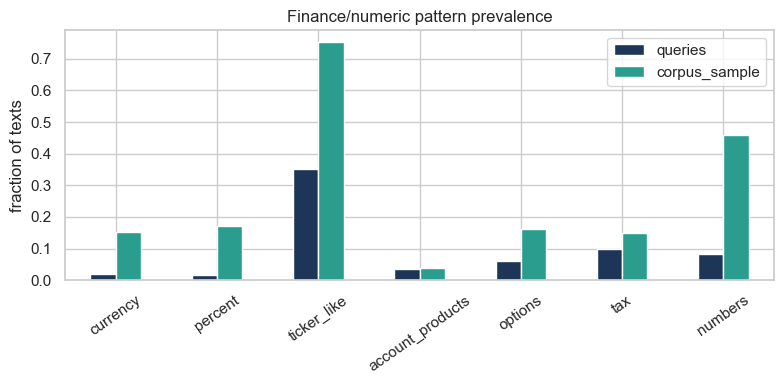

retirement_accounts: 4.1% of queries mention at least one term
equity: 19.2% of queries mention at least one term
fixed_income: 2.1% of queries mention at least one term


In [9]:
PATTERNS = {
    "currency": re.compile(r"\$\d+|\b(?:usd|eur|gbp)\b", re.I),
    "percent": re.compile(r"\d+(?:\.\d+)?%|\bpercent(?:age)?\b", re.I),
    "ticker_like": re.compile(r"\b[A-Z]{1,5}\b"),
    "account_products": re.compile(r"\b(?:401\(?k\)?|ira|roth|hsa|529)\b", re.I),
    "options": re.compile(r"\b(?:call|put|strike|premium|option(?:s)?)\b", re.I),
    "tax": re.compile(r"\b(?:tax|taxes|irs|deduction|capital gains?)\b", re.I),
    "numbers": re.compile(r"\b\d+(?:\.\d+)?\b"),
}


def pattern_rate_series(series: pd.Series, name: str) -> pd.Series:
    rates = {p: series.map(lambda t: bool(rx.search(t))).mean() for p, rx in PATTERNS.items()}
    return pd.Series(rates, name=name)


q_rates = pattern_rate_series(queries["text"], "queries")
c_rates = pattern_rate_series(corpus.sample(5000, random_state=42)["text"], "corpus_sample")
pattern_tbl = pd.concat([q_rates, c_rates], axis=1)
display(pattern_tbl)

fig, ax = plt.subplots(figsize=(8, 4))
pattern_tbl.plot(kind="bar", ax=ax, color=["#1d3557", "#2a9d8f"])
ax.set_title("Finance/numeric pattern prevalence")
ax.set_ylabel("fraction of texts")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

concept_groups = {
    "retirement_accounts": ["401k", "ira", "roth", "pension", "retirement"],
    "equity": ["stock", "stocks", "equity", "share", "shares"],
    "fixed_income": ["bond", "bonds", "treasury", "yield", "coupon"],
}

q_tok_sets = queries["text"].map(lambda t: set(tokenize(t)))
for group, terms in concept_groups.items():
    hits = q_tok_sets.map(lambda s: any(t in s for t in terms))
    print(f"{group}: {hits.mean():.1%} of queries mention at least one term")


## 8. Qualitative review — gold pairs & hard cases


In [10]:
queries_by_id = queries.set_index("_id")["text"]
corpus_by_id = corpus.set_index("_id")["text"]

gold_with_cov = gold.copy()
gold_with_cov["query_coverage"] = [
    overlap_coeff(query_tok[q], corpus_tok[d]) for q, d in zip(gold["query-id"], gold["corpus-id"])
]
gold_with_cov["jaccard"] = [
    jaccard(query_tok[q], corpus_tok[d]) for q, d in zip(gold["query-id"], gold["corpus-id"])
]

print("=== High lexical overlap gold pairs ===")
high = gold_with_cov.nlargest(5, "query_coverage")
for _, row in high.iterrows():
    print("-" * 80)
    print(f"Q ({row['query-id']}) cov={row['query_coverage']:.2f}: {queries_by_id[row['query-id']]}")
    print(f"D ({row['corpus-id']}): {corpus_by_id[row['corpus-id']][:350]}")

print("\n=== Low lexical overlap gold pairs (semantic / paraphrase risk) ===")
low = gold_with_cov.nsmallest(5, "query_coverage")
for _, row in low.iterrows():
    print("-" * 80)
    print(f"Q ({row['query-id']}) cov={row['query_coverage']:.2f}: {queries_by_id[row['query-id']]}")
    print(f"D ({row['corpus-id']}): {corpus_by_id[row['corpus-id']][:350]}")


=== High lexical overlap gold pairs ===
--------------------------------------------------------------------------------
Q (5641) cov=1.00: Google market cap
D (156467): You are right: if the combined value of all outstanding GOOG shares was $495B, and the combined value of all GOOGL shares was $495B, then yes, Alphabet would have a market cap of at least $990B (where I say at least only because I myself don't know that there aren't other issues that should be in the count as well). The respective values of the tot
--------------------------------------------------------------------------------
Q (6717) cov=1.00: Would I qualify for a USDA loan?
D (592780): How realistic is it that I will be able to get a home within the 250,000 range in the next year or so?  Very unlikely in the next year.  The debt/income ratio isn't good enough, and your credit score needs to show at least a year of regular payments without late or default issues before you can start asking for mortgages in this ran

In [11]:
sample_qids = list(qrels["train"].groupby("query-id").size().nlargest(20).index[:5])

for qid in sample_qids:
    qtext = queries_by_id[qid]
    gold_docs = qrels["train"].loc[qrels["train"]["query-id"] == qid, "corpus-id"].tolist()
    cand = RNG.choice(corpus_id_list, size=200, replace=False)
    scored = sorted(
        ((overlap_coeff(query_tok[qid], corpus_tok[d]), d) for d in cand if d not in set(gold_docs)),
        reverse=True,
    )
    best_neg_cov, best_neg = scored[0]
    print("=" * 80)
    print(f"QUERY {qid}: {qtext}")
    print(f"GOLD ({gold_docs[0]}) cov={overlap_coeff(query_tok[qid], corpus_tok[gold_docs[0]]):.2f}")
    print(corpus_by_id[gold_docs[0]][:280])
    print(f"DISTRACTOR ({best_neg}) cov={best_neg_cov:.2f}")
    print(corpus_by_id[best_neg][:280])


QUERY 1505: What options do I have at 26 years old, with 1.2 million USD?
GOLD (172778) cov=0.79
The amount of money you have should be enough for you to live a safe but somewhat restricted life if you never worked again - but it could set you up for just about any sort of financial goal (short of island buying) if you do just about any amount of work. The basic math for som
DISTRACTOR (375877) cov=0.57
There is really much simpler explanation for the interest rate differences in different countries. It is the interest rate arbitrage. It is a very well explored economic concept, so you can look it up on the Internet, in case you want to know more. 1) Interest rates for the same 
QUERY 3012: Why buy insurance?
GOLD (257715) cov=0.67
"Because people are Risk Averse. Suppose that you own an asset worth $10,000 to you.  Suppose that each year, the asset has 1% chance of being stolen (or completely broken).  The expected value is 99% x 10,000 + 1% x $0 = $9,900. This is the average outcome 

## 9. Takeaways for baseline design


In [12]:
takeaways = {
    "n_corpus": len(corpus),
    "n_queries": len(queries),
    "titles_usable": bool((~corpus["title_empty"]).any() or (~queries["title_empty"]).any()),
    "relevance_graded": any((df["score"] != 1).any() for df in qrels.values()),
    "mean_rel_per_query_test": float(qrels["test"].groupby("query-id").size().mean()),
    "pct_corpus_ever_relevant": len(all_relevant_docs) / len(corpus),
    "mean_gold_query_coverage": float(gold_stats["query_coverage"].mean()),
    "mean_neg_query_coverage": float(neg_stats["query_coverage"].mean()),
    "pct_gold_zero_overlap": float((gold_stats["query_coverage"] == 0).mean()),
    "bm25_gold_gt_random": float(paired.mean()),
}

display(pd.Series(takeaways).to_frame("value"))

print(
    """
Design implications
-------------------
1. Index `text` only — titles are empty in this FiQA dump.
2. Labels are binary and sparse (~2-3 relevants/query) -> Recall@10 / MRR@10 / NDCG@10 are appropriate;
   do not treat unlabeled docs as hard negatives without care.
3. Keep train/dev/test query splits as given; no query leakage observed if overlaps are 0.
4. If gold lexical coverage >> random and BM25 separates well -> start with BM25 baseline.
5. Non-trivial zero-overlap gold pairs => add dense or hybrid retrieval after the lexical baseline.
6. Currency/percent/account tokens are common — preserve numbers and symbols in tokenization;
   consider finance synonym expansion later (401k/IRA/Roth), not in the first baseline.
"""
)


,value
n_corpus,57638
n_queries,6648
titles_usable,False
relevance_graded,False
mean_rel_per_query_test,2.632716
pct_corpus_ever_relevant,0.296853
mean_gold_query_coverage,0.481292
mean_neg_query_coverage,0.220637
pct_gold_zero_overlap,0.024
bm25_gold_gt_random,0.904



Design implications
-------------------
1. Index `text` only — titles are empty in this FiQA dump.
2. Labels are binary and sparse (~2-3 relevants/query) -> Recall@10 / MRR@10 / NDCG@10 are appropriate;
   do not treat unlabeled docs as hard negatives without care.
3. Keep train/dev/test query splits as given; no query leakage observed if overlaps are 0.
4. If gold lexical coverage >> random and BM25 separates well -> start with BM25 baseline.
5. Non-trivial zero-overlap gold pairs => add dense or hybrid retrieval after the lexical baseline.
6. Currency/percent/account tokens are common — preserve numbers and symbols in tokenization;
   consider finance synonym expansion later (401k/IRA/Roth), not in the first baseline.

